# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(https://movlendash.streamlit.app/)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [21]:
# Your data checks here
#step 1: Check the shape of the dataset
df.shape
#step 2: Check the data types of each column
df.dtypes
#step 3: Check for missing values in the dataset
df.isnull().sum()
#step 4: Check for duplicate rows in the dataset
df.duplicated().sum()
#step 5: Check for unique values in each column
df.nunique()
#step 6: Check for summary statistics of the dataset
df.describe()
#step 7: Check for correlation between numerical columns
df.corr(numeric_only=True)


,user_id,movie_id,rating,age,year,decade,rating_year
user_id,1.000000,0.010377,-0.009371,-0.073599,-0.001585,-0.002705,0.015775
movie_id,0.010377,1.000000,-0.189124,-0.012612,0.019687,0.011914,0.044126
rating,-0.009371,-0.189124,1.000000,0.054460,-0.175992,-0.168764,-0.036020
age,-0.073599,-0.012612,0.054460,1.000000,-0.125851,-0.128495,0.099767
year,-0.001585,0.019687,-0.175992,-0.125851,1.000000,0.987256,0.002126
decade,-0.002705,0.011914,-0.168764,-0.128495,0.987256,1.000000,-0.003025
rating_year,0.015775,0.044126,-0.036020,0.099767,0.002126,-0.003025,1.000000


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Unique rated movies; genres split on | and counted once per tag (not a pie)
- Why:

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Mean of individual ratings after the same explode; Film-Noir highest, Fantasy lowest
- Why:

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Mean rating vs release year, not rating timestamp
- Why:

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Top 5 by mean among movies with at least N ratings; slider default 50, raise to 150 to drop the Wallace & Gromit shorts
- Why:

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

In [36]:
# Q1: your code here
df = pd.read_csv("../data/movie_ratings.csv")

rated_movies = df[["movie_id", "genres"]].drop_duplicates()
genre_movies = rated_movies.assign(
    genre=rated_movies["genres"].str.split("|")
).explode("genre")

genre_summary = (
    genre_movies.groupby("genre")["movie_id"]
    .nunique()
    .rename("num_of_movies")
    .to_frame()
)

genre_summary["share_of_movies(%)"] = (
    genre_summary["num_of_movies"] / rated_movies["movie_id"].nunique() * 100
)

genre_summary = genre_summary.sort_values("num_of_movies", ascending=False)
genre_summary

,num_of_movies,share_of_movies(%)
genre,,
Drama,725,43.103448
Comedy,505,30.023781
Action,251,14.922711
Thriller,251,14.922711
Romance,247,14.684899
Adventure,135,8.026159
Children,122,7.253270
Crime,109,6.480380
Sci-Fi,101,6.004756


**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_
The top 3 genres are Drama(725), Comedy(505), Action & Thriller (251, tied). We found this by counting how many this specific genre was listed (most genres were listed together due to movies having multiple genres), then dividing it by the total count of movies to get the percentage.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

In [37]:
# Q2: your code here
df = pd.read_csv("../data/movie_ratings.csv")
#head & tail of genres sorted by avg rating
genre_avg_rating = (
    df.groupby("genres")["rating"]
    .mean()
    .sort_values(ascending=False) ) 
genre_avg_rating.head(3), genre_avg_rating.tail(3)

(genres
 Animation|Comedy|Thriller    4.491071
 Animation                    4.430556
 Sci-Fi|War                   4.252577
 Name: rating, dtype: float64,
 genres
 Children|Fantasy             2.066667
 Action|Adventure|Children    1.800000
 Fantasy                      1.000000
 Name: rating, dtype: float64)

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_ Animation|Comedy|Thriller    4.491071
 Animation                    4.430556
 Sci-Fi|War                   4.252577
 Name: rating, dtype: float64,
 genres
 Children|Fantasy             2.066667
 Action|Adventure|Children    1.800000
 Fantasy                      1.000000

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

<Axes: title={'center': 'Average Rating of Movies by Year'}, xlabel='year'>

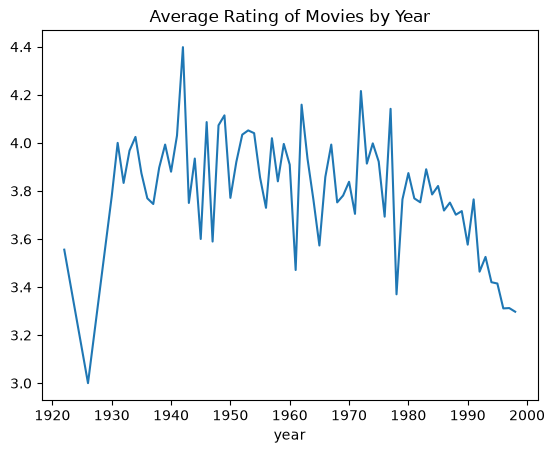

In [41]:
# Q3: your code here
df = pd.read_csv("../data/movie_ratings.csv")
year_avg_rating = df.groupby("year")["rating"].mean()
year_avg_rating.plot(kind="line", title="Average Rating of Movies by Year")


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_
Downward trend, could say people are more generous/picky with their ratings now or as more & more films come out or get rated later their rating gets toward the median rating

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [ ]:
# Q4: your code here
df = pd.read_csv("../data/movie_ratings.csv")
#top 5 movies with highest average rating with atleast 50 ratings
top_movies_50ct = (
    df.groupby("movie_id")
    .agg(title=("title", "first"), avg_rating=("rating", "mean"), num_ratings=("rating", "count"))
    .query("num_ratings >= 50")
    .sort_values("avg_rating", ascending=False)
    .head(5)
)
top_movies_50ct

top_movie_150ct = (
    df.groupby("movie_id")
    .agg(title=("title", "first"), avg_rating=("rating", "mean"), num_ratings=("rating", "count"))
    .query("num_ratings >= 150")
    .sort_values("avg_rating", ascending=False)
    .head(5)
)
top_movie_150ct

#show both top 5 movies with atleast 50 ratings and top 5 movies with atleast 150 ratings
top_movies = pd.concat([top_movies_50ct, top_movie_150ct], keys=["At least 50 ratings", "At least 150 ratings"])
top_movies

title  \
                     movie_id                                                      
At least 50 ratings  408                                   Close Shave, A (1995)   
                     318                                 Schindler's List (1993)   
                     169                              Wrong Trousers, The (1993)   
                     483                                       Casablanca (1942)   
                     114       Wallace & Gromit: The Best of Aardman Animatio...   
At least 150 ratings 318                                 Schindler's List (1993)   
                     483                                       Casablanca (1942)   
                     64                         Shawshank Redemption, The (1994)   
                     603                                      Rear Window (1954)   
                     12                               Usual Suspects, The (1995)   

                               avg_rating  num_ratings  
                     movie_id                           
At least 50 ratings  408         4.491071          112  
                     318         4.466443          298  
                     169         4.466102          118  
                     483         4.456790          243  
                     114         4.447761           67  
At least 150 ratings 318         4.466443          298  
                     483         4.456790          243  
                     64          4.445230          283  
                     603         4.387560          209  
                     12          4.385768          267

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_
The movies with fewer # of ratings dropped, & the movies with more # of ratings came in. Smaller samples (# of ratings) are stronger yet somewhat inflated.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
Create a plan so we can create live, publically accessible dashboard URL with the given the "movie_rating.csv" in @data. Before we start, answer these following questions:

Q1: What's the distribution of genres among the movies that were rated? We know that movies can have multiple genres, so elaborate on how you handle movies with multiple genres for this? 

Q2: Which genres have the highest average rating? Which have the lowest?

Q3:How has the mean rating changed across movie release years?

Q4:hat are the top 5 best-rated movies, once you only count movies with at least 50 ratings? What changes if you raise that floor to 150?

- AI's first attempt: 
I have the four answers from the CSV and your choice of a new public GitHub repo. I’ll put those findings and the Streamlit deploy steps into the plan.
(A PLAN FILE)

- What I changed (or accepted without checking): 
Asked it to fix labeling & scaling & to copy & push it on Streamlit

**Prompt 2**
- What I asked:
The local run is from the file on my computer right. The URL runs on the files from the MovLenDash github correct? Both app.py on the local files & the MovLenDash files are basically the same right? For Q4 bar's chart lets make it a vertical bar chart (not histogram) & have it's X-axis increment be 0.5. Lets add some more color to the graphs as well (mainly the bar graphs). 
- AI's first attempt:
I’ll confirm local vs GitHub vs the live URL, then compare both app.py files and plan the Q4 chart and color changes
(A PLAN FILE)
- What I changed (or accepted without checking): Accepted the graph change & color push

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Drama (724), Comedy (505), Action & Thriller (251)
- I say: Drama (724), Comedy (505), Action & Thriller (251)
- Same? (yes / partly / no): Yes
- If different, why?

**Q2**
- Dashboard says: Genre Satisfaction with the mean of indivudal ratings or movies tagged with each genre (the same explode rule)
- I say: Top 3 genres with highest rating & top 3 genres with lowest rating
- Same? (yes / partly / no): No
- If different, why? Different rubrics

**Q3**
- Dashboard says: Trend uses movie release year, not the year the rating was submitted. Sparse early years make the line jumpy; 1990s titles dominate this dataset.
- I say: Average rating by year
- Same? (yes / partly / no): Yes
- If different, why?

**Q4**
- Dashboard says: Broken chart of top 5 movies with atleast 50 ratings
- I say: Table with top 5 movies with atleast 50 ratings & 150 ratings
- Same? (yes / partly / no): partly
- If different, why? ran out of tokens/credits

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horiztonal Bar graph
- Chart I used: Table
- Which communicates the answer better, and why? visually the dashboard, but numbers wise the table

**Q2**
- Chart the dashboard used: horizontal bar graph   
- Chart I used: Table
- Which communicates the answer better, and why? visually the dashboard, but numbers wise the table

**Q3**
- Chart the dashboard used: line plot
- Chart I used: line plot
- Which communicates the answer better, and why? both is same

**Q4**
- Chart the dashboard used: broken histogram?
- Chart I used: table
- Which communicates the answer better, and why? i like my table more

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

Other than my broken graph in the bottom  for the dashboard yeah. The stuff I did here in these cells kinda, but its valid

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.


**✏️ Your answers:** _(label each one with its number)_

5) The genres with least amount of movies & least amount of ratings would inflate the chart as they have less information meaning that they are skewed.



## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): 
AI did the last graph the worst, mine is simply a table so isnt bad for people who can read

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):
The other charts the AI did was pretty good

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?
My agent took in all the info & did it for me for the first week so it was driving itself, naturally I drove myself for this weeks.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week